In [4]:
%pip install google-play-scraper pandas

In [5]:
from google_play_scraper import reviews, Sort, app
import pandas as pd
from datetime import datetime

APP_ID = 'br.com.gerenciadorfinanceiro.controller'

# Confirma que o app existe
info = app(APP_ID, lang='pt', country='br')
print(info['title'], '| nota geral:', info['score'], '| total de avaliações:', info['ratings'])

# Coleta de 200 avaliações mais recentes
resultado, _ = reviews(
    APP_ID,
    lang='pt',
    country='br',
    sort=Sort.NEWEST,
    count=200
)

df_bruto = pd.DataFrame(resultado)

# Mantém só as variáveis previstas no documento da fonte
df_bruto = df_bruto[['score', 'content', 'at', 'thumbsUpCount']]
df_bruto.columns = ['nota', 'comentario', 'data', 'curtidas']

# Salva o arquivo ORIGINAL (nunca editar este arquivo)
df_bruto.to_csv('mobills_avaliacoes_originais.csv', index=False, encoding='utf-8-sig')

print('Quantidade coletada:', len(df_bruto))
print('Período:', df_bruto['data'].min(), 'até', df_bruto['data'].max())
print('Data da coleta:', datetime.now().strftime('%d/%m/%Y %H:%M'))
df_bruto.head()

Mobills: Finanças Pessoais | nota geral: 4.169644 | total de avaliações: 293558
Quantidade coletada: 200
Período: 2026-10-01 23:32:07 até 2026-11-20 18:51:48
Data da coleta: 21/11/2026 19:11


,nota,comentario,data,curtidas
0,2,horrivel e gastei um dinheiro atoa. comprei o ...,2026-11-20 18:51:48,0
1,5,estou gostando muito,2026-11-20 11:33:19,0
2,1,Usei uma vez e a experiência foi muito ruim. B...,2026-11-20 05:06:58,0
3,5,app incrível recomendo de mais super intuitivo...,2026-11-20 02:43:54,0
4,5,Excelente! ainda não usei o plano PRO (mais av...,2026-11-19 17:17:19,0


2.1 — Indicadores de Desempenho (KPIs) e Justificativas


In [6]:

# KPIs - PROJETO LIFESYNC

import pandas as pd

# Carrega a coleta correta de 06/11/2026
df = pd.read_csv(
    '/content/mobills_avaliacoes_tratadas_coleta_06-11-2026.csv',
    parse_dates=['data']
)

print('Avaliações carregadas:', len(df))
print(df['classe_nota'].value_counts())



total = len(df)

nota_media = df['nota'].mean()

taxa_positivas = (
    (df['nota'] >= 4).sum() / total
) * 100

taxa_negativas = (
    (df['nota'] <= 2).sum() / total
) * 100

print("=== KPIs DO PROJETO LIFESYNC ===")
print(f"Total de avaliações: {total}")
print(f"Nota média: {nota_media:.2f}")
print(f"Taxa de avaliações positivas: {taxa_positivas:.1f}%")
print(f"Taxa de avaliações negativas: {taxa_negativas:.1f}%")


Avaliações carregadas: 200
classe_nota
positiva    122
negativa     67
neutra       11
Name: count, dtype: int64
=== KPIs DO PROJETO LIFESYNC ===
Total de avaliações: 200
Nota média: 3.56
Taxa de avaliações positivas: 61.0%
Taxa de avaliações negativas: 33.5%


In [7]:
print(df_bruto.info())
print('\nNulos por coluna:\n', df_bruto.isnull().sum())
print('\nDuplicados:', df_bruto.duplicated().sum())
print('\nComentários vazios:', (df_bruto['comentario'].fillna('').str.strip() == '').sum())
print('\nDistribuição das notas:\n', df_bruto['nota'].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   nota        200 non-null    int64         
 1   comentario  200 non-null    object        
 2   data        200 non-null    datetime64[ns]
 3   curtidas    200 non-null    int64         
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 6.4+ KB
None

Nulos por coluna:
 nota          0
comentario    0
data          0
curtidas      0
dtype: int64

Duplicados: 0

Comentários vazios: 0

Distribuição das notas:
 nota
1     60
2     15
3     14
4     11
5    100
Name: count, dtype: int64


### Justificativa dos KPIs

Os indicadores de desempenho foram definidos para apoiar o objetivo SMART do projeto LifeSync, que prevê analisar 200 avaliações públicas do aplicativo Mobills até 12 de novembro de 2026, identificando características valorizadas e dificuldades relatadas pelos usuários.

**KPI 1 — Nota média:** permite avaliar o nível geral de satisfação dos usuários na amostra analisada.

**KPI 2 — Taxa de avaliações positivas:** identifica a proporção de avaliações de 4 e 5 estrelas, auxiliando na identificação de experiências favoráveis.

**KPI 3 — Taxa de avaliações negativas:** identifica a proporção de avaliações de 1 e 2 estrelas, orientando a investigação dos problemas relatados pelos usuários.

Esses indicadores contribuem para o levantamento de necessidades e a definição de requisitos conceituais do LifeSync. Entretanto, como os dados pertencem ao aplicativo Mobills, eles não representam indicadores de desempenho operacional do LifeSync.


2.2 — Métodos Estatísticos Essenciais


```
# Isto está formatado como código
```



In [8]:
import glob
import pandas as pd

arquivos = glob.glob('/content/mobills_avaliacoes_tratadas_col*.csv')

print("Arquivos encontrados:", arquivos)

df = pd.read_csv(arquivos[0], parse_dates=['data'])

print("Total de avaliações:", len(df))
print(df['classe_nota'].value_counts())


Arquivos encontrados: ['/content/mobills_avaliacoes_tratadas_coleta_06-11-2026.csv']
Total de avaliações: 200
classe_nota
positiva    122
negativa     67
neutra       11
Name: count, dtype: int64


In [9]:
# 2.2 — Métodos Estatísticos Essenciais

print("=== ANÁLISE ESTATÍSTICA — LIFESYNC ===")

print(f"Média: {df['nota'].mean():.2f}")
print(f"Mediana: {df['nota'].median():.2f}")
print(f"Desvio padrão: {df['nota'].std():.2f}")
print(f"Assimetria: {df['nota'].skew():.2f}")

=== ANÁLISE ESTATÍSTICA — LIFESYNC ===
Média: 3.56
Mediana: 5.00
Desvio padrão: 1.76
Assimetria: -0.57


### Interpretação dos resultados estatísticos

A análise das 200 avaliações públicas do aplicativo Mobills apresentou média de 3,56 estrelas e mediana de 5 estrelas. Essa diferença indica que, embora a avaliação central seja elevada, existem notas baixas que reduzem a média geral.

O desvio padrão de 1,76 demonstra uma dispersão considerável das avaliações, sugerindo experiências distintas entre os usuários. A assimetria de -0,57 indica uma distribuição com maior concentração nas notas altas e uma cauda voltada para as notas baixas.

Esses resultados contribuem para o diagnóstico do projeto LifeSync, pois reforçam a importância de identificar tanto as funcionalidades valorizadas quanto as dificuldades relatadas pelos usuários de aplicativos de gestão financeira.

In [10]:

from scipy.stats import spearmanr, pearsonr

# Relação entre tamanho do comentário e nota
x = df['tamanho_comentario']
y = df['nota']

# Correlações
pearson, p_pearson = pearsonr(x, y)
spearman, p_spearman = spearmanr(x, y)

print("=== ANÁLISE DE CORRELAÇÃO ===")
print(f"Pearson: {pearson:.3f} | p-valor: {p_pearson:.4f}")
print(f"Spearman: {spearman:.3f} | p-valor: {p_spearman:.4f}")


=== ANÁLISE DE CORRELAÇÃO ===
Pearson: -0.638 | p-valor: 0.0000
Spearman: -0.660 | p-valor: 0.0000


### Interpretação da análise de correlação

A análise das 200 avaliações do aplicativo Mobills identificou uma correlação negativa entre o tamanho dos comentários e as notas atribuídas pelos usuários. O coeficiente de Pearson foi de -0,638 e o de Spearman foi de -0,660, indicando uma associação negativa moderada a forte entre as variáveis.

Os testes apresentaram p-valores inferiores a 0,0001, demonstrando que a associação observada é estatisticamente significativa. Assim, na amostra analisada, comentários mais extensos tendem a acompanhar avaliações mais baixas.

Esse resultado contribui para o projeto LifeSync ao indicar que comentários detalhados, especialmente aqueles associados a avaliações negativas, merecem atenção na identificação das dificuldades dos usuários. Entretanto, a correlação não estabelece uma relação de causa e efeito.

Análise de Outliers


In [11]:

# ANÁLISE DE OUTLIERS - LIFESYNC
# Método: Intervalo Interquartil (IQR)

# Primeiro e terceiro quartis
Q1 = df['tamanho_comentario'].quantile(0.25)
Q3 = df['tamanho_comentario'].quantile(0.75)

# Intervalo interquartil
IQR = Q3 - Q1

# Limites para identificar outliers
limite_inferior = max(0, Q1 - 1.5 * IQR)
limite_superior = Q3 + 1.5 * IQR

# Identificar comentários fora dos limites
outliers = df[
    (df['tamanho_comentario'] < limite_inferior) |
    (df['tamanho_comentario'] > limite_superior)
]

# Resultados
print("=== ANÁLISE DE OUTLIERS ===")
print(f"Primeiro quartil (Q1): {Q1:.2f}")
print(f"Terceiro quartil (Q3): {Q3:.2f}")
print(f"Intervalo interquartil: {IQR:.2f}")
print(f"Limite superior: {limite_superior:.2f}")
print(f"Quantidade de outliers: {len(outliers)}")
print(f"Percentual: {len(outliers)/len(df)*100:.1f}%")

# Mostrar os 10 comentários mais longos
print("\n=== COMENTÁRIOS MAIS LONGOS ===")
print(
    df[['nota', 'tamanho_comentario', 'comentario']]
    .sort_values('tamanho_comentario', ascending=False)
    .head(10)
    .to_string(index=False)
)


=== ANÁLISE DE OUTLIERS ===
Primeiro quartil (Q1): 4.00
Terceiro quartil (Q3): 32.50
Intervalo interquartil: 28.50
Limite superior: 75.25
Quantidade de outliers: 8
Percentual: 4.0%

=== COMENTÁRIOS MAIS LONGOS ===
 nota  tamanho_comentario                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         comentario
    1                  87                                        Não cumpre o que promete O app não sincroniza direito com os bancos, soma saldo com seu lá o que, não aparece o cartão que é vinculado a conta. Assinei o Premium e estou tentando cancelar desde a 

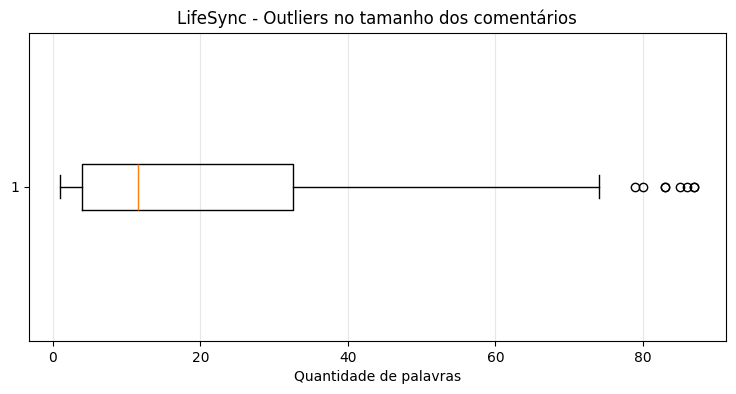

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.boxplot(
    df['tamanho_comentario'],
    vert=False
)

plt.title('LifeSync - Outliers no tamanho dos comentários')
plt.xlabel('Quantidade de palavras')
plt.grid(axis='x', alpha=0.3)

plt.show()


### Interpretação da análise de outliers

A análise de outliers foi realizada utilizando o método do intervalo interquartil (IQR), aplicado à quantidade de palavras dos comentários. O primeiro quartil foi de 4 palavras e o terceiro quartil de 32,5 palavras, resultando em um intervalo interquartil de 28,5 palavras.

O limite superior calculado foi de 75,25 palavras, permitindo identificar 8 comentários considerados atípicos, correspondentes a 4% das 200 avaliações analisadas.


O gráfico Boxplot evidencia que a maioria dos comentários apresenta extensão relativamente reduzida, enquanto uma pequena parcela contém textos significativamente maiores. Esses registros podem fornecer informações detalhadas sobre a experiência dos usuários e contribuir para a identificação de necessidades relevantes ao projeto LifeSync.

Ressalta-se que o tamanho do comentário, isoladamente, não permite determinar se a avaliação é positiva ou negativa. Para isso, é necessária a análise de seu conteúdo.

2.3 — Visualização de Dados


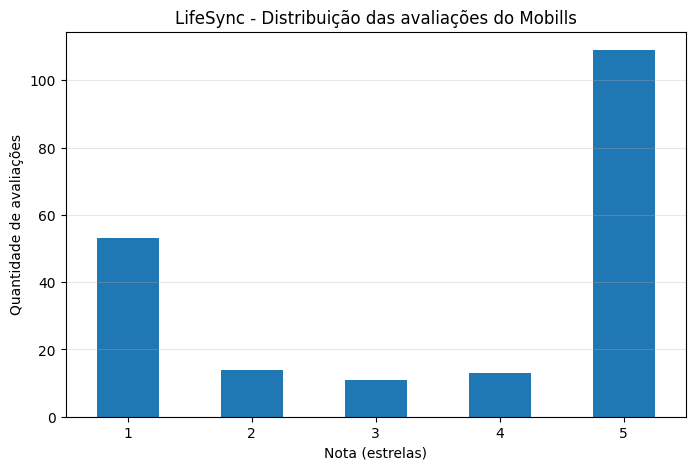

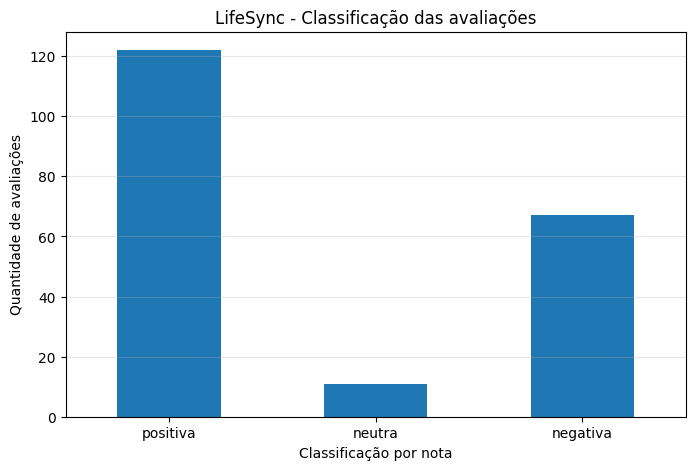

In [13]:

import matplotlib.pyplot as plt

# GRÁFICO 1 - Distribuição das notas
contagem = df['nota'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
contagem.plot(kind='bar')

plt.title('LifeSync - Distribuição das avaliações do Mobills')
plt.xlabel('Nota (estrelas)')
plt.ylabel('Quantidade de avaliações')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

# GRÁFICO 2 - Classificação das avaliações
classes = df['classe_nota'].value_counts().reindex(
    ['positiva', 'neutra', 'negativa']
)

plt.figure(figsize=(8, 5))
classes.plot(kind='bar')

plt.title('LifeSync - Classificação das avaliações')
plt.xlabel('Classificação por nota')
plt.ylabel('Quantidade de avaliações')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()


### Interpretação dos gráficos de distribuição das avaliações

O primeiro gráfico apresenta a distribuição das notas atribuídas pelos usuários do aplicativo Mobills. Entre as 200 avaliações analisadas, 109 receberam 5 estrelas e 53 receberam 1 estrela, evidenciando uma concentração nas avaliações extremas.

O segundo gráfico apresenta a classificação das avaliações por nota. Observou-se que 61% foram classificadas como positivas (4 ou 5 estrelas), 33,5% como negativas (1 ou 2 estrelas) e 5,5% como neutras (3 estrelas).

Embora a maioria das avaliações seja positiva, a proporção de avaliações negativas é relevante e indica a necessidade de investigar as dificuldades relatadas pelos usuários. Para o projeto conceitual LifeSync, esses resultados ajudam a fundamentar o levantamento de requisitos e a identificação de oportunidades de melhoria.

É importante destacar que os dados representam uma amostra de 200 avaliações recentes do Mobills, não a totalidade de seus usuários.


Análise das principais reclamações dos usuários

=== PRINCIPAIS TEMAS NAS AVALIAÇÕES NEGATIVAS ===
Total de avaliações negativas: 67
Sincronização           25
Falhas técnicas         20
Saldos e lançamentos    19
Cobranças e preços      15
Usabilidade              1

Avaliações sem categoria identificada: 14


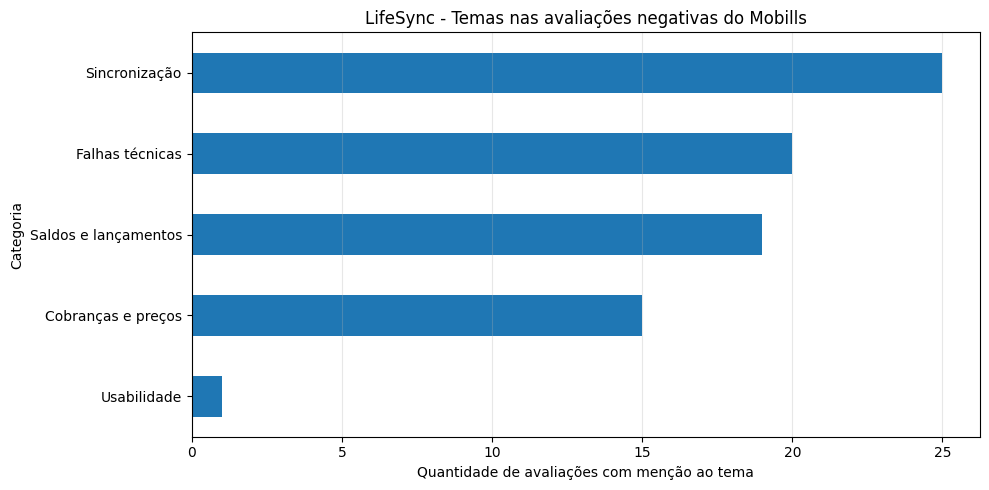

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
import unicodedata
import re

# Selecionar avaliações negativas (1 ou 2 estrelas)
negativas = df[df['nota'] <= 2].copy()

# Normalizar texto para facilitar a busca
def normalizar(texto):
    texto = str(texto).lower()
    texto = unicodedata.normalize('NFKD', texto)
    texto = ''.join(
        c for c in texto if not unicodedata.combining(c)
    )
    return texto

negativas['texto_analise'] = negativas['comentario'].apply(normalizar)

# Categorias exploratórias e palavras-chave
categorias = {
    'Sincronização': [
        r'sincroniz', r'conect', r'integrac', r'banco'
    ],
    'Falhas técnicas': [
        r'bug', r'erro', r'trav', r'falh',
        r'nao abre', r'nao funciona'
    ],
    'Cobranças e preços': [
        r'cobranc', r'cobrou', r'caro',
        r'preco', r'assinatura', r'premium'
    ],
    'Saldos e lançamentos': [
        r'saldo', r'lancamento', r'despesa',
        r'receita', r'valor errado'
    ],
    'Usabilidade': [
        r'interface', r'confus', r'dificil',
        r'complicad', r'botao', r'tela'
    ]
}

# Contar quantas avaliações mencionam cada categoria
contagens = {}

for categoria, palavras in categorias.items():
    padrao = '|'.join(palavras)
    contagens[categoria] = negativas['texto_analise'].str.contains(
        padrao, regex=True, na=False
    ).sum()

resultado = pd.Series(contagens).sort_values(ascending=False)

print('=== PRINCIPAIS TEMAS NAS AVALIAÇÕES NEGATIVAS ===')
print(f'Total de avaliações negativas: {len(negativas)}')
print(resultado.to_string())

# Avaliações sem correspondência nas categorias
padrao_geral = '|'.join(
    palavra
    for lista in categorias.values()
    for palavra in lista
)

sem_categoria = (~negativas['texto_analise'].str.contains(
    padrao_geral, regex=True, na=False
)).sum()

print(f'\nAvaliações sem categoria identificada: {sem_categoria}')

# Gráfico
plt.figure(figsize=(10, 5))
resultado.sort_values().plot(kind='barh')

plt.title('LifeSync - Temas nas avaliações negativas do Mobills')
plt.xlabel('Quantidade de avaliações com menção ao tema')
plt.ylabel('Categoria')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretação dos principais temas das avaliações negativas

A análise exploratória das 67 avaliações negativas do aplicativo Mobills, classificadas por notas de 1 ou 2 estrelas, identificou os principais temas mencionados nos comentários por meio de palavras-chave.

O tema mais frequente foi sincronização, presente em 25 avaliações (37,3%), seguido por falhas técnicas, com 20 menções (29,9%), saldos e lançamentos, com 19 (28,4%), cobranças e preços, com 15 (22,4%), e usabilidade, com 1 menção (1,5%). Outras 14 avaliações não apresentaram correspondência com as categorias definidas.

Os resultados sugerem que a sincronização de informações e a confiabilidade do funcionamento do aplicativo são pontos relevantes para investigação. Para o projeto conceitual LifeSync, essas evidências podem orientar a definição de requisitos não funcionais relacionados à confiabilidade, à integridade dos dados e à facilidade de uso.

Como a classificação foi realizada automaticamente por palavras-chave, os resultados devem ser interpretados como menções a temas, e não como uma identificação definitiva de reclamações. Uma mesma avaliação pode mencionar mais de uma categoria.

### 2.4 — Análise Crítica e Conexão com o TAP

A análise de 200 avaliações públicas do aplicativo Mobills identificou 67 avaliações negativas (33,5%) e uma nota média de 3,56 estrelas. A correlação entre o tamanho dos comentários e a nota atribuída apresentou coeficientes de Pearson de -0,638 e Spearman de -0,660, indicando uma associação negativa entre a extensão dos relatos e a avaliação dos usuários. A análise de outliers identificou 8 comentários com tamanho atípico (4% da amostra). Na classificação exploratória das avaliações negativas, a sincronização foi o tema mais mencionado, com 25 correspondências por palavras-chave, equivalentes a 37,3% das 67 avaliações negativas. A leitura desses comentários revelou relatos recorrentes de falhas de atualização, dificuldades de integração bancária e divergências entre saldos, faturas e lançamentos. Embora algumas correspondências estejam relacionadas a outros assuntos, os relatos indicam que a confiabilidade das informações financeiras é um ponto relevante para investigação. Esses resultados não comprovam, por si só, a existência de um gargalo operacional interno do Mobills, mas permitem identificar dificuldades percebidas pelos usuários.

Essas evidências contribuem para justificar o projeto conceitual LifeSync, conforme os objetivos definidos no Termo de Abertura do Projeto (TAP), especialmente a identificação das necessidades do público-alvo, a definição de requisitos funcionais e não funcionais e a realização de análises de dados. Os resultados sugerem priorizar, no planejamento da solução, requisitos relacionados à integridade dos registros financeiros, à clareza das informações apresentadas, à prevenção de inconsistências e à facilidade de uso. Como o LifeSync não prevê integração bancária real nem desenvolvimento de uma aplicação funcional, essas recomendações serão tratadas na documentação conceitual. Dessa forma, a análise dos dados públicos do Mobills fornece subsídios para decisões de escopo e planejamento, respeitando as limitações da amostra e sem atribuir ao LifeSync problemas operacionais de outro aplicativo.

In [15]:

# VERIFICAÇÃO DOS COMENTÁRIOS SOBRE SINCRONIZAÇÃO

# Selecionar avaliações negativas que mencionam o tema
padrao_sincronizacao = '|'.join(
    categorias['Sincronização']
)

comentarios_sincronizacao = negativas[
    negativas['texto_analise'].str.contains(
        padrao_sincronizacao,
        regex=True,
        na=False
    )
].copy()

print("=== COMENTÁRIOS SOBRE SINCRONIZAÇÃO ===")
print("Quantidade encontrada:", len(comentarios_sincronizacao))

# Mostrar os comentários para conferência
for numero, (_, linha) in enumerate(
    comentarios_sincronizacao.iterrows(), start=1
):
    print(f"\n--- Avaliação {numero} ---")
    print("Nota:", linha['nota'])
    print("Comentário:", linha['comentario'])


=== COMENTÁRIOS SOBRE SINCRONIZAÇÃO ===
Quantidade encontrada: 25

--- Avaliação 1 ---
Nota: 1
Comentário: Tão ruim que cancelei com 4 dias e estão negando o reembolso. Fujam! não sincroniza no open finance e a forma de leitura da fatura do cartão é péssima e não ajuda a rastrear os gastos mês a mês

--- Avaliação 2 ---
Nota: 1
Comentário: Puro Roubo, só rouba seu dinheiro!!!! Pra você conectar pelo menos um cartão pelo o Opem finance você tem que pagar obrigatoriamente o prêmio pra ser "Usuário prêmio... Se não pagar e totalmente inútil o aplicativo o Valor e 200 reais, e o aplicativo de finanças mais roubado atualmente ficando em 1 lugar⚠️🥇 existe outro milhões de aplicativo que são muito mais melhorar e ainda Tem IA e só cobrar o pouco. Com o valor do usuário prêmio você consegue pagar milhões de aplicativo de Finanças👎

--- Avaliação 3 ---
Nota: 1
Comentário: Fiquei bastante frustrada quando fui fazer a integração da conta bancária, e simplesmente o aplicativo mexeu em todos os sal

In [16]:
from google.colab import files
files.download('mobills_avaliacoes_originais.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import pandas as pd
import re

# 1. Carrega o arquivo ORIGINAL (nunca é alterado)
df = pd.read_csv('mobills_avaliacoes_originais.csv', parse_dates=['data'])
print('Registros originais:', len(df))

# 2. Padronização do texto
def limpar_texto(t):
    t = str(t).strip().lower()
    t = re.sub(r'\s+', ' ', t)   # espaços repetidos viram um só
    return t

df['comentario_limpo'] = df['comentario'].apply(limpar_texto)

# 3. Remove duplicados após a padronização (pega "Top" e "top ")
antes = len(df)
df = df.drop_duplicates(subset=['nota', 'comentario_limpo', 'data'])
print('Duplicados removidos após padronização:', antes - len(df))

# 4. Colunas derivadas (úteis para a análise)
df['tamanho_comentario'] = df['comentario_limpo'].str.split().str.len()
df['comentario_curto'] = df['tamanho_comentario'] < 5   # ex.: "top", "muito bom"
df['mes'] = df['data'].dt.to_period('M').astype(str)

def classificar(n):
    if n <= 2: return 'negativa'
    if n == 3: return 'neutra'
    return 'positiva'

df['classe_nota'] = df['nota'].apply(classificar)

# 5. Validação
assert df['nota'].between(1, 5).all(), 'Existe nota fora de 1 a 5'
assert (df['curtidas'] >= 0).all(), 'Existe curtida negativa'

# 6. Salva a base TRATADA (arquivo separado do original)
df.to_csv('mobills_avaliacoes_tratadas.csv', index=False, encoding='utf-8-sig')

print('Registros finais:', len(df))
print(df['classe_nota'].value_counts())
print('Comentários curtos:', df['comentario_curto'].sum())
df.head()


Registros originais: 200
Duplicados removidos após padronização: 0
Registros finais: 200
classe_nota
positiva    111
negativa     75
neutra       14
Name: count, dtype: int64
Comentários curtos: 56


,nota,comentario,data,curtidas,comentario_limpo,tamanho_comentario,comentario_curto,mes,classe_nota
0,2,horrivel e gastei um dinheiro atoa. comprei o ...,2026-11-20 18:51:48,0,horrivel e gastei um dinheiro atoa. comprei o ...,35,False,2026-11,negativa
1,5,estou gostando muito,2026-11-20 11:33:19,0,estou gostando muito,3,True,2026-11,positiva
2,1,Usei uma vez e a experiência foi muito ruim. B...,2026-11-20 05:06:58,0,usei uma vez e a experiência foi muito ruim. b...,54,False,2026-11,negativa
3,5,app incrível recomendo de mais super intuitivo...,2026-11-20 02:43:54,0,app incrível recomendo de mais super intuitivo...,13,False,2026-11,positiva
4,5,Excelente! ainda não usei o plano PRO (mais av...,2026-11-19 17:17:19,0,excelente! ainda não usei o plano pro (mais av...,19,False,2026-11,positiva


In [18]:
from google.colab import files
files.download('mobills_avaliacoes_tratadas.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:

import pandas as pd

df = pd.read_csv(
    '/content/mobills_avaliacoes_tratadas_coleta_06-11-2026.csv',
    parse_dates=['data']
)

print(df['classe_nota'].value_counts())


classe_nota
positiva    122
negativa     67
neutra       11
Name: count, dtype: int64


In [20]:

# VALIDAÇÃO FINAL DA BASE UTILIZADA NO RELATÓRIO

print("=== VALIDAÇÃO FINAL - LIFESYNC ===")

print("Total de registros:", len(df))
print("Valores nulos:", df.isnull().sum().sum())
print("Duplicados:", df.duplicated().sum())

print("Notas válidas:", df['nota'].between(1, 5).all())
print("Curtidas válidas:", (df['curtidas'] >= 0).all())

print("\nDistribuição das avaliações:")
print(df['classe_nota'].value_counts())

print("\nPeríodo analisado:")
print(df['data'].min(), "até", df['data'].max())

# Confere se estamos usando a base do relatório
assert len(df) == 200, "Quantidade de registros incorreta"
assert (df['nota'] >= 4).sum() == 122, "Base diferente da utilizada no relatório"
assert (df['nota'] <= 2).sum() == 67, "Base diferente da utilizada no relatório"
assert (df['nota'] == 3).sum() == 11, "Base diferente da utilizada no relatório"

print("\nBase validada! Os dados correspondem ao relatório.")


=== VALIDAÇÃO FINAL - LIFESYNC ===
Total de registros: 200
Valores nulos: 0
Duplicados: 0
Notas válidas: True
Curtidas válidas: True

Distribuição das avaliações:
classe_nota
positiva    122
negativa     67
neutra       11
Name: count, dtype: int64

Período analisado:
2026-09-13 20:57:08 até 2026-11-05 03:47:59

Base validada! Os dados correspondem ao relatório.
